# 🎬 Análisis de sentimiento en reseñas de películas (IMDB)

**Objetivo:** entrenar un modelo de clasificación que identifique si una reseña de película es **positiva** o **negativa**.

**Flujo del notebook**

1. Importar paquetes
2. Exploración de los datos
3. Reflexión inicial y preparación de datos (subconjunto balanceado + split train/test)
4. De texto a números (TF-IDF)
5. Entrenamiento (SVM)
6. Evaluación (accuracy, F1, reporte de clasificación, matriz de confusión)
7. **Siguientes pasos (tarea):** comparar con `LogisticRegression`, `GaussianNB` y `DecisionTreeClassifier`

> Importante: el modelo **no "entiende" el lenguaje**. Convierte el texto en números (vectorización) y aprende patrones estadísticos sobre ellos.

## 1. Importar paquetes

| Paquete | Para qué lo usamos | Por qué lo elegimos |
|---|---|---|
| `numpy` | operaciones numéricas con arreglos | base de todo el ecosistema científico de Python |
| `pandas` | cargar el CSV y manipular tablas (`DataFrame`) | forma estándar de manejar datos tabulares |
| `matplotlib` / `seaborn` | gráficas | `seaborn` simplifica gráficas estadísticas sobre `matplotlib` |
| `train_test_split` | separar datos de entrenamiento y prueba | evita evaluar con los mismos datos con los que se entrenó |
| `TfidfVectorizer` | convertir texto a vectores numéricos | los modelos de ML solo aceptan números |
| `SVC` | clasificador de máquinas de vectores de soporte | funciona muy bien con texto (alta dimensionalidad) |
| `BeautifulSoup` / `re` | limpiar HTML y texto con expresiones regulares | las reseñas de IMDB traen etiquetas como `<br />` |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from bs4 import BeautifulSoup
import re

# Estilo de fondo con cuadrícula para todas las gráficas de seaborn
sns.set_style('darkgrid')

## 2. Exploración

Antes de modelar hay que conocer los datos: tamaño, tipos, columnas y balance de clases.

In [2]:
# read_csv carga el archivo en un DataFrame. Se usa ruta relativa para que funcione en Windows, Linux y WSL.
df = pd.read_csv("./data/IMDB Dataset.csv")

# info() muestra número de filas, columnas, tipos y si hay valores nulos (aquí no los hay).
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


Tenemos **50,000 filas y 2 columnas**, ambas de tipo texto (`object`) y sin nulos, así que no hace falta imputar valores.

Veamos algunas observaciones al azar. `sample(5)` es mejor que `head()` porque `head()` solo muestra las primeras filas, que pueden no ser representativas.

In [3]:
df.sample(5)

,review,sentiment
19187,"And my children love it now! Granted, I can wa...",positive
36683,"OK, the story - a simpleminded loony enters a ...",negative
44968,The Sopranos is arguably the greatest show in ...,positive
33077,"I've seen this film so many times, It's that g...",positive
29468,"""The fallen ones"" falls under the waste of lif...",negative


Las columnas son:

- **review**: texto de la reseña (no sabemos de qué película es, ni importa para este análisis).
- **sentiment**: etiqueta `positive` o `negative`. Es la variable que queremos **predecir** (*target*).

Revisamos el balance de clases con `value_counts()`: si una clase dominara, el modelo podría sesgarse hacia ella.

In [4]:
df.sentiment.value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Hay **25,000 reseñas positivas y 25,000 negativas**: el dataset está perfectamente balanceado.

### Nota sobre el HTML en las reseñas

Si miras las reseñas verás etiquetas `<br />` (saltos de línea de HTML). Para eso se importaron `BeautifulSoup` y `re`. Veamos cómo limpiarlas en un ejemplo:

In [5]:
ejemplo = "Great movie!<br /><br />I loved it. <b>Really</b>."

# BeautifulSoup interpreta el HTML y get_text() devuelve solo el texto, sin etiquetas.
limpio = BeautifulSoup(ejemplo, "html.parser").get_text(separator=" ")

# re.sub reemplaza cualquier secuencia de espacios en blanco por un solo espacio.
limpio = re.sub(r"\s+", " ", limpio).strip()
print(limpio)

Great movie! I loved it. Really .


En este notebook **seguimos el flujo de la lección** y no aplicamos esta limpieza al entrenamiento (por eso más adelante aparecerá el token `br` entre las palabras importantes). Aplicarla sería una mejora válida para un siguiente experimento.

## 3. Reflexión inicial

El modelo parecerá "comprender" que *"I really loved this movie"* es positiva, pero lo que hace es **vectorizar** el texto (convertirlo en listas de números) y buscar patrones. No hay comprensión en el sentido humano, sino una interpretación matemática.

## 4. Preparación de datos

El entrenamiento con 50,000 reseñas es pesado, así que para fines demostrativos usamos **5,000 positivas + 5,000 negativas** (10,000 en total), manteniendo el balance.

In [6]:
# Filtramos por clase con una máscara booleana y [:5000] toma las primeras 5,000 filas de cada una.
df_pos = df[df['sentiment'] == 'positive'][:5000]
df_neg = df[df['sentiment'] == 'negative'][:5000]

# concat une ambos DataFrames (uno debajo del otro) en uno solo de 10,000 filas.
df_reviews = pd.concat([df_pos, df_neg])
df_reviews.shape

(10000, 2)

### Split entrenamiento / prueba

- `test_size=0.33`: 33% de los datos se reservan para evaluar con reseñas que el modelo **nunca vio** (si evaluáramos con los datos de entrenamiento obtendríamos una métrica inflada).
- `random_state=42`: fija la semilla aleatoria para que el resultado sea **reproducible**.

Después separamos cada conjunto en `x` (el texto, entrada) y `y` (la etiqueta, salida).

In [7]:
train, test = train_test_split(df_reviews, test_size=0.33, random_state=42)

train_x, train_y = train['review'], train['sentiment']
test_x, test_y = test['review'], test['sentiment']

Verificamos que el entrenamiento siga razonablemente balanceado (el split es aleatorio, así que no será exactamente 50/50):

In [8]:
train_y.value_counts()

sentiment
negative    3378
positive    3322
Name: count, dtype: int64

## 5. De texto a números: TF-IDF

Usamos `TfidfVectorizer` de Scikit-Learn. **TF-IDF** combina dos ideas:

- **TF (Term Frequency):** qué tan frecuente es una palabra *dentro de una reseña*.
- **IDF (Inverse Document Frequency):** penaliza las palabras que aparecen en *casi todas las reseñas* (no ayudan a distinguir una de otra).

Una palabra obtiene puntaje alto si es frecuente en una reseña pero rara en el resto.

Argumento `stop_words='english'`: elimina palabras muy comunes del inglés ("the", "and", "is"...) que no aportan información sobre el sentimiento y solo añaden ruido y dimensiones.

**Detalle clave — `fit_transform` vs `transform`:**
- `fit_transform` en entrenamiento: **aprende** el vocabulario y los IDF, y transforma.
- `transform` en prueba: usa el vocabulario ya aprendido. Si hiciéramos `fit` también en prueba habría **fuga de información** (*data leakage*).

In [9]:
tfidf = TfidfVectorizer(stop_words='english')

train_x_vector = tfidf.fit_transform(train_x)   # aprende vocabulario + transforma entrenamiento
test_x_vector = tfidf.transform(test_x)         # solo transforma prueba con el vocabulario aprendido

Inspeccionemos los objetos antes y después de transformar. Antes: reseñas en formato texto (`shape` de una `Series` es `(n,)`).

In [10]:
train_x.shape

(6700,)

In [11]:
train_x_vector.shape

(6700, 44107)

Ahora es una matriz con **una fila por reseña y una columna por palabra única del vocabulario** (decenas de miles de columnas).

Veamos su tipo:

In [12]:
type(train_x_vector)

scipy.sparse._csr.csr_matrix

Es un `csr_matrix` (*Compressed Sparse Row*), una **matriz dispersa**: como cada reseña solo usa una pequeña fracción del vocabulario, casi todo son ceros. En vez de guardar todos los ceros, solo se guardan los valores distintos de cero y su posición, ahorrando mucha memoria y tiempo.

Pandas puede convertirla a un `DataFrame` disperso con `from_spmatrix` (usamos el índice original y los nombres de las palabras como columnas):

In [13]:
pd.DataFrame.sparse.from_spmatrix(train_x_vector,
                                  index=train_x.index,
                                  columns=tfidf.get_feature_names_out())

,00,000,007,00am,00s,01,01pm,02,04,05,...,émigré,émigrés,était,étc,être,ísnt,île,önsjön,über,überwoman
6746,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
54,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8499,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7869,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3725,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1501,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
358,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
761,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1685,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Son demasiados ceros para ver algo útil. Tomemos **una sola reseña**; primero el texto original:

In [14]:
train_x.iloc[0]

"I happened to rent this movie with my sister in hopes of watching a great entertaining movie, that was humorous, however my expectations were let down. This movie was beyond disgusting and revolting for a PG-13 movie, this should have been rated R for the many mature references that went on in this movie. I wouldn't recommend allowing a 13 year old teen see this.<br /><br />Even if no one under the age of 17 is watching this movie, beware of a truly stupid movie, there's no humor in the movie, just a bunch of disgusting sexual references including a small touch of pedophilia, something that shouldn't even be joked about. <br /><br />I would like to know what happened to PG-13 movies, that were actually safe for actual a 13 year old? This is beyond a deplorable movie and should be re-rated."

Ahora su fila en la matriz (`.iloc[0]` toma la primera fila). Sigue siendo casi todo ceros:

In [15]:
primera_resenia = pd.DataFrame.sparse.from_spmatrix(train_x_vector,
                                                    index=train_x.index,
                                                    columns=tfidf.get_feature_names_out()).iloc[0]
primera_resenia

00           0.0
000          0.0
007          0.0
00am         0.0
00s          0.0
            ... 
ísnt         0.0
île          0.0
önsjön       0.0
über         0.0
überwoman    0.0
Name: 6746, Length: 44107, dtype: Sparse[float64, 0.0]

Filtramos solo lo que **no** es cero, es decir, las palabras que sí aparecen en esa reseña:

In [16]:
primera_resenia[primera_resenia != 0]

13               0.45849
17               0.12824
actual          0.091601
actually        0.061461
age             0.088765
allowing         0.12824
beware          0.143046
br              0.124945
bunch           0.093128
deplorable      0.168137
disgusting      0.237945
entertaining    0.081088
expectations    0.103149
great           0.048868
happened        0.176853
hopes           0.114028
humor           0.084465
humorous        0.116516
including       0.087603
joked           0.168137
just            0.037675
know            0.053984
let              0.07195
like            0.036454
mature          0.126021
movie           0.276309
movies            0.0522
old             0.123513
pedophilia      0.172712
pg              0.260154
rated           0.206643
recommend       0.076198
references      0.226901
rent            0.093234
revolting       0.151971
safe            0.119732
sexual          0.098677
shouldn         0.108203
sister          0.095008
small           0.078916


Cada número es el peso TF-IDF de la palabra: mientras más alto, más relevante es para **esa** reseña en comparación con el resto. Observa también el token `br`, resto del HTML `<br />`.

## 6. Entrenamiento: Máquinas de Vectores de Soporte (SVM)

**¿Por qué SVM?** Maneja bien la **alta dimensionalidad** del texto (aquí decenas de miles de columnas), es efectiva en **clasificación binaria** y generaliza bien a reseñas no vistas.

- `kernel='linear'`: busca un hiperplano que separe las dos clases. En texto TF-IDF las clases suelen ser casi linealmente separables, y el kernel lineal es rápido y evita sobreajuste.
- `fit(X, y)`: ajusta el modelo con los vectores de entrenamiento y sus etiquetas.

In [17]:
svc = SVC(kernel='linear')
svc.fit(train_x_vector, train_y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Probemos con reseñas nuevas. Hay que pasarlas por el **mismo** `tfidf` (con `transform`) para que usen el mismo vocabulario con el que se entrenó el modelo. `predict` espera una lista de textos, de ahí los corchetes.

In [18]:
print(svc.predict(tfidf.transform(['A good movie'])))
print(svc.predict(tfidf.transform(['An excellent movie'])))
print(svc.predict(tfidf.transform(['I did not like this movie at all'])))

['positive']
['positive']
['negative']


**Interpretación:** las tres frases se clasificaron como esperábamos (*A good movie* y *An excellent movie* → `positive`; *I did not like this movie at all* → `negative`). Son pocos ejemplos, así que solo sirven como prueba rápida; la evaluación seria viene a continuación con 3,300 reseñas de prueba.

## 7. Evaluación

Necesitamos métricas objetivas, y siempre sobre el **conjunto de prueba**.

In [19]:
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

### Precisión (*accuracy*)

La más simple: proporción de predicciones correctas sobre el total. `score` predice sobre `test_x_vector` y lo compara con `test_y`. Es adecuada aquí porque las clases están balanceadas (con clases desbalanceadas engaña).

In [20]:
print(svc.score(test_x_vector, test_y))

0.8706060606060606


**Interpretación:** `0.8706` significa que el modelo acertó ≈ **87.06%** de las reseñas del conjunto de prueba (unas 2,873 de 3,300), todas ellas reseñas que nunca vio durante el entrenamiento.

### F1 Score

Media armónica de *precision* y *recall*.

- **Precision:** de lo que el modelo dijo "positivo", ¿cuánto lo era realmente?
- **Recall:** de lo que realmente era positivo, ¿cuánto detectó el modelo?

`average=None` devuelve un valor por clase, en el orden indicado en `labels`: `[positive, negative]`.

In [21]:
f1_score(test_y, svc.predict(test_x_vector),
         labels=['positive', 'negative'], average=None)

array([0.87400413, 0.86701962])

**Interpretación:** `0.874` es el F1 de la clase `positive` y `0.867` el de `negative`. Son muy parecidos, así que el modelo rinde de forma pareja en ambas clases, con una ligera ventaja en las positivas (≈ 0.7 puntos).

### Reporte de clasificación

Resume *precision*, *recall*, *f1-score* y *support* (cuántas muestras reales hay por clase) en una sola tabla. `macro avg` promedia las clases sin pesarlas; `weighted avg` las pondera por su `support`.

In [22]:
print(classification_report(test_y, svc.predict(test_x_vector),
                            labels=['positive', 'negative']))

              precision    recall  f1-score   support

    positive       0.87      0.88      0.87      1678
    negative       0.88      0.86      0.87      1622

    accuracy                           0.87      3300
   macro avg       0.87      0.87      0.87      3300
weighted avg       0.87      0.87      0.87      3300



**Interpretación:**

- **Precision:** 0.87 en `positive` y 0.88 en `negative`. Cuando el modelo dice "positiva" acierta el 87% de las veces, y cuando dice "negativa", el 88%.
- **Recall:** 0.88 en `positive` y 0.86 en `negative`. Detecta el 88% de las reseñas realmente positivas y el 86% de las realmente negativas.
- **Support:** 1,678 positivas y 1,622 negativas en el conjunto de prueba (3,300 en total), casi balanceado.
- **Accuracy global:** 0.87. Como las clases están balanceadas, `macro avg` y `weighted avg` coinciden en 0.87 y confirman un rendimiento uniforme.

### Matriz de confusión

Filas = clase real, columnas = clase predicha (en el orden de `labels`):

|  | pred. positive | pred. negative |
|---|---|---|
| **real positive** | Verdaderos positivos (VP) | Falsos negativos (FN) |
| **real negative** | Falsos positivos (FP) | Verdaderos negativos (VN) |

In [23]:
conf_mat = confusion_matrix(test_y, svc.predict(test_x_vector),
                            labels=['positive', 'negative'])
conf_mat

array([[1481,  197],
       [ 230, 1392]])

**Interpretación** (filas = real, columnas = predicho):

- **1481** reseñas positivas bien clasificadas como positivas (verdaderos positivos).
- **197** reseñas positivas que el modelo clasificó como negativas (falsos negativos).
- **230** reseñas negativas que el modelo clasificó como positivas (falsos positivos).
- **1392** reseñas negativas bien clasificadas (verdaderos negativos).

Aciertos: 1481 + 1392 = 2873 de 3300 (87.06%, igual que el accuracy). El modelo comete algo más de errores sobre reseñas negativas (230) que sobre positivas (197), lo que concuerda con su recall ligeramente menor en `negative` (0.86 contra 0.88).

Una matriz de números se lee mejor como mapa de calor (`seaborn.heatmap`; `annot=True` escribe el valor en cada celda y `fmt='d'` lo muestra como entero):

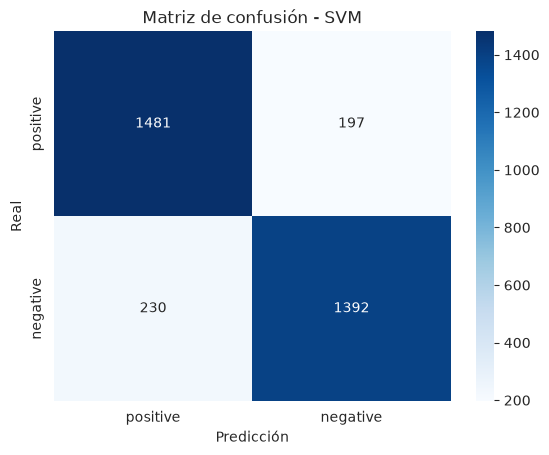

In [24]:
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=['positive', 'negative'],
            yticklabels=['positive', 'negative'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de confusión - SVM')
plt.show()

El mapa de calor muestra lo mismo que la matriz: la **diagonal** (celdas oscuras) son los aciertos y las celdas fuera de ella, los errores.

## 8. Siguientes pasos (tarea)

Ahora comparamos si SVM fue la mejor elección, entrenando con **los mismos datos de entrenamiento y prueba** (para que la comparación sea justa) estos modelos:

1. `LogisticRegression`
2. `GaussianNB`
3. `DecisionTreeClassifier`

Para no repetir código definimos una función que evalúa cualquier modelo y guarda sus métricas.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

resultados = {}   # aquí iremos guardando las métricas de cada modelo

def evaluar(nombre, modelo, X_test, y_test=test_y):
    """Predice con el modelo ya entrenado, guarda accuracy y F1 macro, e imprime el reporte."""
    pred = modelo.predict(X_test)
    resultados[nombre] = {
        'accuracy': accuracy_score(y_test, pred),
        'f1_macro': f1_score(y_test, pred, average='macro'),
    }
    print(f"=== {nombre} ===")
    print(classification_report(y_test, pred, labels=['positive', 'negative']))
    print("Matriz de confusión [positive, negative]:")
    print(confusion_matrix(y_test, pred, labels=['positive', 'negative']))

# Registramos también el SVM ya entrenado para compararlo
evaluar('SVM (lineal)', svc, test_x_vector)

=== SVM (lineal) ===
              precision    recall  f1-score   support

    positive       0.87      0.88      0.87      1678
    negative       0.88      0.86      0.87      1622

    accuracy                           0.87      3300
   macro avg       0.87      0.87      0.87      3300
weighted avg       0.87      0.87      0.87      3300

Matriz de confusión [positive, negative]:
[[1481  197]
 [ 230 1392]]


### 8.1 Regresión logística

A pesar del nombre es un **clasificador**: calcula la probabilidad de pertenecer a una clase con una función sigmoide. Es un clásico para texto: rápido, bien comportado con datos dispersos y de alta dimensionalidad, y sus coeficientes son interpretables. Acepta directamente la matriz dispersa.

In [26]:
logreg = LogisticRegression(max_iter=1000)   # max_iter alto para asegurar que el optimizador converja
logreg.fit(train_x_vector, train_y)
evaluar('Regresión logística', logreg, test_x_vector)

=== Regresión logística ===
              precision    recall  f1-score   support

    positive       0.87      0.88      0.87      1678
    negative       0.88      0.86      0.87      1622

    accuracy                           0.87      3300
   macro avg       0.87      0.87      0.87      3300
weighted avg       0.87      0.87      0.87      3300

Matriz de confusión [positive, negative]:
[[1479  199]
 [ 224 1398]]


### 8.2 Naive Bayes Gaussiano (`GaussianNB`)

Asume que cada característica sigue una distribución normal e independiente de las demás.

⚠️ **Limitación práctica:** `GaussianNB` **no acepta matrices dispersas**, hay que convertirlas a densas con `.toarray()`. Con ~44,000 columnas la matriz densa ocuparía ≈2.4 GB de RAM (6,700 × 44,107 números de 8 bytes), así que para este modelo usamos un vectorizador con `max_features=5000` (conserva solo las 5,000 palabras más frecuentes). Los datos de entrenamiento/prueba son los mismos; solo cambia la cantidad de columnas, y debemos tenerlo en cuenta al comparar.

In [27]:
tfidf_denso = TfidfVectorizer(stop_words='english', max_features=5000)
train_x_denso = tfidf_denso.fit_transform(train_x).toarray()   # .toarray(): sparse -> denso
test_x_denso = tfidf_denso.transform(test_x).toarray()

gnb = GaussianNB()
gnb.fit(train_x_denso, train_y)
evaluar('GaussianNB', gnb, test_x_denso)

=== GaussianNB ===
              precision    recall  f1-score   support

    positive       0.79      0.75      0.77      1678
    negative       0.75      0.80      0.77      1622

    accuracy                           0.77      3300
   macro avg       0.77      0.77      0.77      3300
weighted avg       0.77      0.77      0.77      3300

Matriz de confusión [positive, negative]:
[[1251  427]
 [ 328 1294]]


### 8.3 Árbol de decisión (`DecisionTreeClassifier`)

Aprende una serie de reglas del tipo "¿la palabra *terrible* tiene peso > x?" para dividir los datos. Es fácil de interpretar, pero con tantas columnas tiende a **sobreajustarse** (memoriza el entrenamiento: en una verificación obtuvo 100% de accuracy en entrenamiento contra 71.6% en prueba). `random_state=42` lo hace reproducible, ya que el árbol desempata aleatoriamente entre características.

In [28]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(train_x_vector, train_y)
evaluar('Árbol de decisión', tree, test_x_vector)

=== Árbol de decisión ===
              precision    recall  f1-score   support

    positive       0.73      0.71      0.72      1678
    negative       0.71      0.72      0.71      1622

    accuracy                           0.72      3300
   macro avg       0.72      0.72      0.72      3300
weighted avg       0.72      0.72      0.72      3300

Matriz de confusión [positive, negative]:
[[1192  486]
 [ 450 1172]]


### 8.4 Comparación final

In [29]:
comparacion = pd.DataFrame(resultados).T.sort_values('f1_macro', ascending=False)
comparacion

,accuracy,f1_macro
Regresión logística,0.871818,0.871741
SVM (lineal),0.870606,0.870512
GaussianNB,0.771212,0.771173
Árbol de decisión,0.716364,0.716353


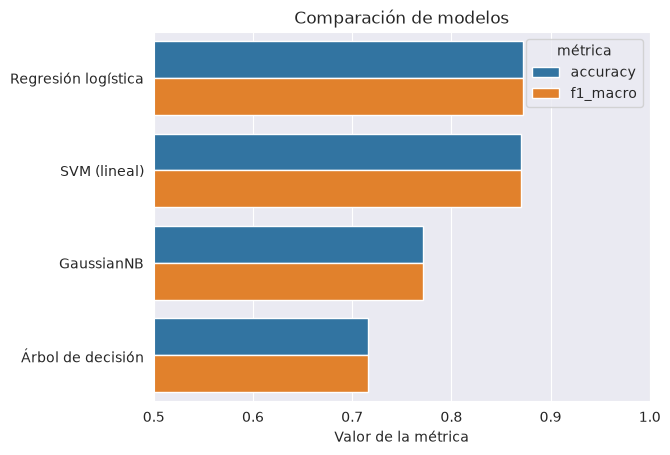

In [30]:
# Barras agrupadas: una por métrica y modelo (melt pasa la tabla a formato largo, el que seaborn necesita)
largo = comparacion.reset_index().melt(id_vars='index', var_name='métrica', value_name='valor')
sns.barplot(data=largo, x='valor', y='index', hue='métrica')
plt.xlim(0.5, 1)    # el eje empieza en 0.5 (azar en 2 clases) para que las diferencias se vean
plt.xlabel('Valor de la métrica')
plt.ylabel('')
plt.title('Comparación de modelos')
plt.show()

### Conclusiones

| Modelo | Accuracy | F1 macro |
|---|---|---|
| Regresión logística | 0.872 | 0.872 |
| SVM (lineal) | 0.871 | 0.871 |
| GaussianNB | 0.771 | 0.771 |
| Árbol de decisión | 0.716 | 0.716 |

- **SVM no fue estrictamente la mejor**: la regresión logística la superó por ~0.1 puntos porcentuales, una diferencia que en la práctica es ruido. Ambos modelos lineales son equivalentes aquí, y la regresión logística entrena bastante más rápido (≈5 s frente a ≈24 s del SVM en una medición hecha en este mismo split; los tiempos varían según el equipo).
- **Los modelos lineales ganan con texto TF-IDF** porque el espacio tiene decenas de miles de dimensiones y las clases son casi linealmente separables.
- **GaussianNB** rinde peor: su supuesto de distribución normal no encaja con pesos TF-IDF (casi todos cero), y además hubo que reducir a 5,000 columnas para poder usar matrices densas.
- **El árbol de decisión** es el peor: sobreajusta (100% en entrenamiento contra 71.6% en prueba).
- Todas las métricas se midieron en un único split; para afirmar que una diferencia tan pequeña es real habría que usar validación cruzada.